# Cap. 3 · Cadena de Markov del estrés
*Proyecto DAT 262 · Monitor de estrés cambiario y monetario de Bolivia*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from stress_monitor import data, stationarity as stat, markov as mk, forecasting as fc, gap as gp, simulation as sim, demo
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
m = data.load_monthly(); d = data.load_daily_key()
print("Datos mensuales:", m.index.min().date(), "→", m.index.max().date(), f"({len(m)} meses)")

Datos mensuales: 1989-01-31 → 2026-10-31 (454 meses)


**Índice de estrés** = promedio de z-scores de −Δ12 log(RIB) y −Δ6 bolivianización **a tipo de cambio constante** (sin efecto de valoración). Estados por percentiles: Tensión ≥ p60, Crisis ≥ p85 (decisión del analista).

In [2]:
ci = mk.stress_index(m); states = mk.classify(ci['indice'])
print('umbrales:', np.round(states.attrs['umbrales'], 2))
ci.tail(6).round(2)

umbrales: [0.32 0.72]


,reservas,bolivianizacion,indice
date,,,
2026-05-31,-1.95,0.49,-0.73
2026-06-30,-0.69,0.58,-0.06
2026-07-31,-0.82,0.46,-0.18
2026-08-31,-1.23,0.37,-0.43
2026-09-30,-0.43,0.36,-0.04
2026-10-31,-0.52,0.28,-0.12


In [3]:
fit = mk.fit_markov(states)
print(pd.DataFrame(fit.P, index=mk.ESTADOS, columns=mk.ESTADOS).round(3))
print('π =', dict(zip(mk.ESTADOS, fit.stationary.round(3))))
print('permanencia (meses) =', dict(zip(mk.ESTADOS, fit.sojourn.round(1))))

         Estable  Tensión  Crisis
Estable    0.932    0.064   0.004
Tensión    0.173    0.709   0.118
Crisis     0.000    0.224   0.776
π = {'Estable': np.float64(0.617), 'Tensión': np.float64(0.244), 'Crisis': np.float64(0.139)}
permanencia (meses) = {'Estable': np.float64(14.7), 'Tensión': np.float64(3.4), 'Crisis': np.float64(4.5)}


Tiempo medio de permanencia en $i$: $1/(1-p_{ii})$. Distribución estacionaria: $\pi P=\pi$.

In [4]:
cur = int(states.iloc[-1]); pr = mk.forecast_state_probs(fit.P, cur)
print('Estado actual:', mk.ESTADOS[cur], states.index[-1].date())
for h, p in pr.items(): print(f'a {h} mes(es):', dict(zip(mk.ESTADOS, p.round(3))))

Estado actual: Estable 2026-10-31
a 1 mes(es): {'Estable': np.float64(0.932), 'Tensión': np.float64(0.064), 'Crisis': np.float64(0.004)}
a 3 mes(es): {'Estable': np.float64(0.838), 'Tensión': np.float64(0.135), 'Crisis': np.float64(0.027)}
a 6 mes(es): {'Estable': np.float64(0.753), 'Tensión': np.float64(0.183), 'Crisis': np.float64(0.064)}


### ¿Se cumple la propiedad de Markov?

In [5]:
print('Independencia χ²:', mk.test_independence(fit.counts))
print('Orden 1 vs 2 (LR):', mk.test_second_order(states))

Independencia χ²: {'chi2': 465.47872798024537, 'gl': 4, 'p_valor': 1.9557365644188055e-99, 'nota': ''}
Orden 1 vs 2 (LR): {'lr': 28.809672971170805, 'gl': 8, 'p_valor': 0.0003424281233059756}


### Validación con episodios y robustez

In [6]:
display(mk.episode_table(states).round(2)); display(mk.robustness(ci['indice']).round(2))

,episodio,meses,Estable,Tensión,Crisis
0,Bonanza 2006-2013,96,0.93,0.01,0.06
1,Caída de reservas 2014-2019,72,0.46,0.46,0.08
2,Pandemia 2020,12,0.00,0.33,0.67
3,Escasez de dólares 2023-2025,35,0.46,0.09,0.46
4,Transición cambiaria dic-2025→may-2026,6,1.00,0.00,0.00
5,Régimen flexible jun-2026→,5,1.00,0.00,0.00


,q_tensión,q_crisis,π Estable,π Tensión,π Crisis,permanencia Estable,permanencia Tensión,permanencia Crisis,P(Estable→Estable),P(Crisis→Crisis)
0,0.50,0.80,0.52,0.29,0.19,13.75,4.12,5.56,0.93,0.82
1,0.60,0.85,0.62,0.24,0.14,14.67,3.44,4.47,0.93,0.78
2,0.67,0.90,0.68,0.22,0.09,16.33,3.40,3.75,0.94,0.73
3,0.70,0.95,0.72,0.24,0.04,18.12,4.78,3.83,0.94,0.74


### Antes y después de 2023 (escasez de dólares)

In [7]:
cmp = mk.compare_periods(states, '2023-01-31')
for k, v in cmp.items():
    print(k, '| n =', v['n'], '|', v.get('aviso', ''))
    if 'P' in v: print(np.round(v['P'], 2))

antes | n = 396 | 
[[0.92 0.07 0.  ]
 [0.17 0.73 0.1 ]
 [0.   0.25 0.75]]
después | n = 46 | 
[[1.   0.   0.  ]
 [0.33 0.   0.67]
 [0.   0.12 0.88]]


Text(0.5, 1.0, 'Índice de estrés y estados')

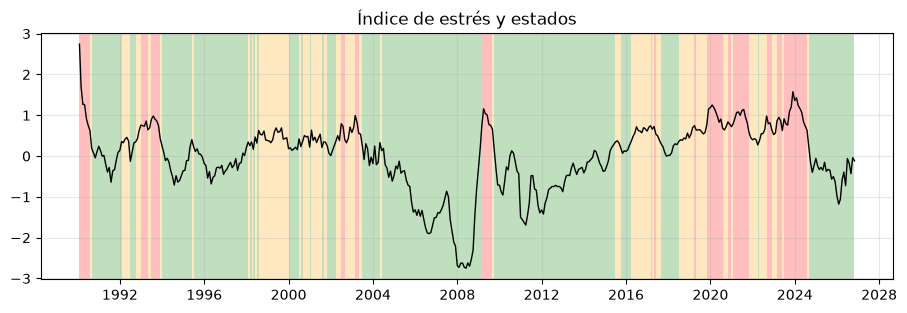

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.2)); ax.plot(ci['indice'], c='k', lw=1)
col = {0: 'green', 1: 'orange', 2: 'red'}
for i in range(len(states) - 1): ax.axvspan(states.index[i], states.index[i + 1], color=col[int(states.iloc[i])], alpha=.25, lw=0)
ax.set_title('Índice de estrés y estados')